In [1]:
# ========== CELL 1: SETUP ==========
from google.colab import drive
drive.mount('/content/drive')

import os
DATA_DIR    = '/content/drive/MyDrive/ResumeProject/data'
RESULTS_DIR = '/content/drive/MyDrive/ResumeProject/results'
APP_DIR     = '/content/drive/MyDrive/ResumeProject/app_models'
EXTRA_DIR   = '/content/drive/MyDrive/ResumeProject/extra_analysis'
os.makedirs(EXTRA_DIR, exist_ok=True)

!pip install -q scikit-learn pandas numpy matplotlib seaborn

import pandas as pd
import numpy as np
import pickle
import torch
import torch.nn as nn
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                              classification_report, r2_score,
                              mean_absolute_error, mean_squared_error)
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge

print("✅ Setup ready")

Mounted at /content/drive
✅ Setup ready


In [2]:
# ========== CELL 2: LOAD DATA + RIDGE MODEL ==========
train = pd.read_csv(f'{DATA_DIR}/train_orig.csv')
test  = pd.read_csv(f'{DATA_DIR}/test.csv')

print(f"Train: {train.shape}, Test: {test.shape}")

# Load saved Ridge model (from app_models)
with open(f'{APP_DIR}/ml_ridge.pkl', 'rb') as f:
    ml_data = pickle.load(f)
vectorizer = ml_data['vectorizer']
ridge = ml_data['model']

# Predict on test
X_test = vectorizer.transform(test['Combined'])
y_test = test['Avg'].values
y_pred = np.clip(ridge.predict(X_test), 0, 1)

print(f"✅ Ridge loaded")
print(f"   Test R²: {r2_score(y_test, y_pred):.4f}")

Train: (241, 12), Test: (61, 11)
✅ Ridge loaded
   Test R²: 0.3811


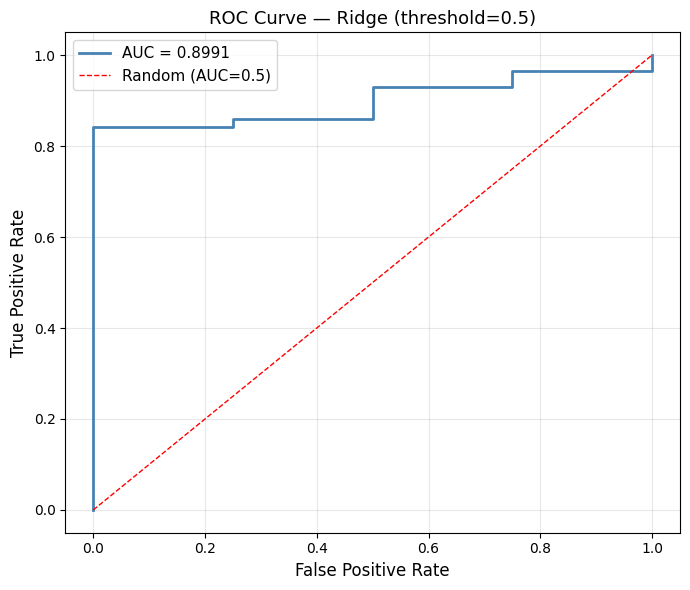

📊 AUC-ROC ANALYSIS — RIDGE
AUC-ROC: 0.8991
Interpretation:
   🟢 Excellent separation

Test set binary split:
   Shortlist (≥0.5): 57 samples
   Reject (<0.5):    4 samples

✅ Saved: /content/drive/MyDrive/ResumeProject/extra_analysis/auc_roc_ridge.png


In [3]:
# ========== CELL 3: AUC-ROC ANALYSIS ==========
# Binary: score >= 0.5 = shortlist (1), else reject (0)
y_test_bin = (y_test >= 0.5).astype(int)

# AUC uses continuous predictions (not thresholded)
auc = roc_auc_score(y_test_bin, y_pred)

# ROC curve
fpr, tpr, _ = roc_curve(y_test_bin, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='steelblue', linewidth=2, label=f'AUC = {auc:.4f}')
ax.plot([0, 1], [0, 1], 'r--', linewidth=1, label='Random (AUC=0.5)')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curve — Ridge (threshold=0.5)', fontsize=13)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{EXTRA_DIR}/auc_roc_ridge.png', dpi=150, bbox_inches='tight')
plt.show()

print("=" * 60)
print("📊 AUC-ROC ANALYSIS — RIDGE")
print("=" * 60)
print(f"AUC-ROC: {auc:.4f}")
print(f"Interpretation:")
if auc > 0.85: print("   🟢 Excellent separation")
elif auc > 0.75: print("   🟡 Good separation")
elif auc > 0.65: print("   🟠 Fair separation")
else: print("   🔴 Poor separation (close to random)")

# Breakdown
n_pos = y_test_bin.sum()
n_neg = len(y_test_bin) - n_pos
print(f"\nTest set binary split:")
print(f"   Shortlist (≥0.5): {n_pos} samples")
print(f"   Reject (<0.5):    {n_neg} samples")

# Save
with open(f'{EXTRA_DIR}/auc_results.txt', 'w') as f:
    f.write(f"AUC-ROC (Ridge): {auc:.4f}\n")
    f.write(f"Positive (>=0.5): {n_pos}\nNegative (<0.5): {n_neg}\n")

print(f"\n✅ Saved: {EXTRA_DIR}/auc_roc_ridge.png")

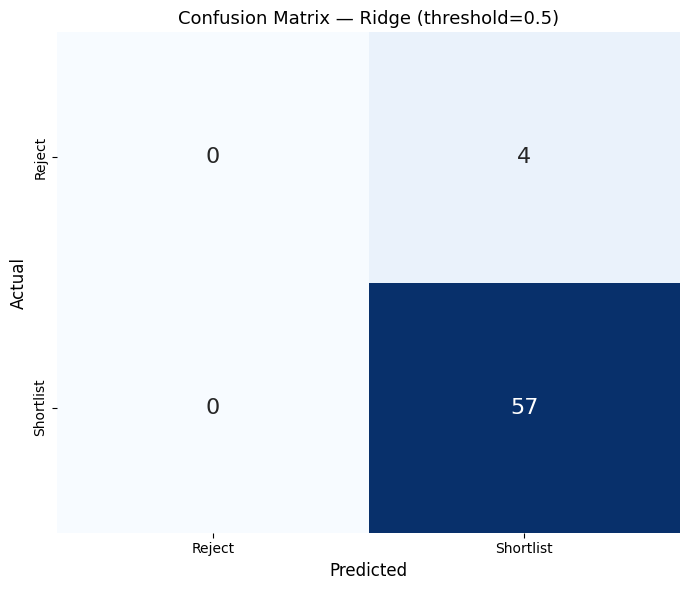

📊 CONFUSION MATRIX — RIDGE
True Negatives (TN):  0  — correctly rejected
False Positives (FP): 4  — wrongly shortlisted
False Negatives (FN): 0  — wrongly rejected
True Positives (TP):  57  — correctly shortlisted

Classification Metrics:
   Accuracy:  0.9344
   Precision: 0.9344  (of shortlisted, how many were correct)
   Recall:    1.0000  (of actual shortlist, how many we caught)
   F1:        0.9661

📋 Full classification report:
              precision    recall  f1-score   support

      Reject       0.00      0.00      0.00         4
   Shortlist       0.93      1.00      0.97        57

    accuracy                           0.93        61
   macro avg       0.47      0.50      0.48        61
weighted avg       0.87      0.93      0.90        61


✅ Saved: /content/drive/MyDrive/ResumeProject/extra_analysis/confusion_matrix_ridge.png


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [4]:
# ========== CELL 4: CONFUSION MATRIX ==========
# Threshold predictions at 0.5
y_pred_bin = (y_pred >= 0.5).astype(int)

cm = confusion_matrix(y_test_bin, y_pred_bin)
tn, fp, fn, tp = cm.ravel()

# Plot
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Reject', 'Shortlist'],
            yticklabels=['Reject', 'Shortlist'],
            cbar=False, annot_kws={'size': 16})
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('Actual', fontsize=12)
ax.set_title('Confusion Matrix — Ridge (threshold=0.5)', fontsize=13)
plt.tight_layout()
plt.savefig(f'{EXTRA_DIR}/confusion_matrix_ridge.png', dpi=150, bbox_inches='tight')
plt.show()

print("=" * 60)
print("📊 CONFUSION MATRIX — RIDGE")
print("=" * 60)
print(f"True Negatives (TN):  {tn}  — correctly rejected")
print(f"False Positives (FP): {fp}  — wrongly shortlisted")
print(f"False Negatives (FN): {fn}  — wrongly rejected")
print(f"True Positives (TP):  {tp}  — correctly shortlisted")

# Derived metrics
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

print(f"\nClassification Metrics:")
print(f"   Accuracy:  {accuracy:.4f}")
print(f"   Precision: {precision:.4f}  (of shortlisted, how many were correct)")
print(f"   Recall:    {recall:.4f}  (of actual shortlist, how many we caught)")
print(f"   F1:        {f1:.4f}")

print(f"\n📋 Full classification report:")
print(classification_report(y_test_bin, y_pred_bin, target_names=['Reject', 'Shortlist']))

# Save
with open(f'{EXTRA_DIR}/confusion_matrix_results.txt', 'w') as f:
    f.write(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}\n")
    f.write(f"Accuracy={accuracy:.4f}, Precision={precision:.4f}, Recall={recall:.4f}, F1={f1:.4f}\n")

print(f"\n✅ Saved: {EXTRA_DIR}/confusion_matrix_ridge.png")

📊 5-FOLD CROSS-VALIDATION — RIDGE
Total samples: 302

   Fold 1: R²=0.4139 | MAE=0.0944 | RMSE=0.1298
   Fold 2: R²=0.3163 | MAE=0.1293 | RMSE=0.2004
   Fold 3: R²=0.3935 | MAE=0.0917 | RMSE=0.1210
   Fold 4: R²=0.4633 | MAE=0.0841 | RMSE=0.1268
   Fold 5: R²=0.3370 | MAE=0.0892 | RMSE=0.1390

📊 Average across 5 folds:
   R²:   0.3848 ± 0.0530
   MAE:  0.0977 ± 0.0161
   RMSE: 0.1434 ± 0.0291


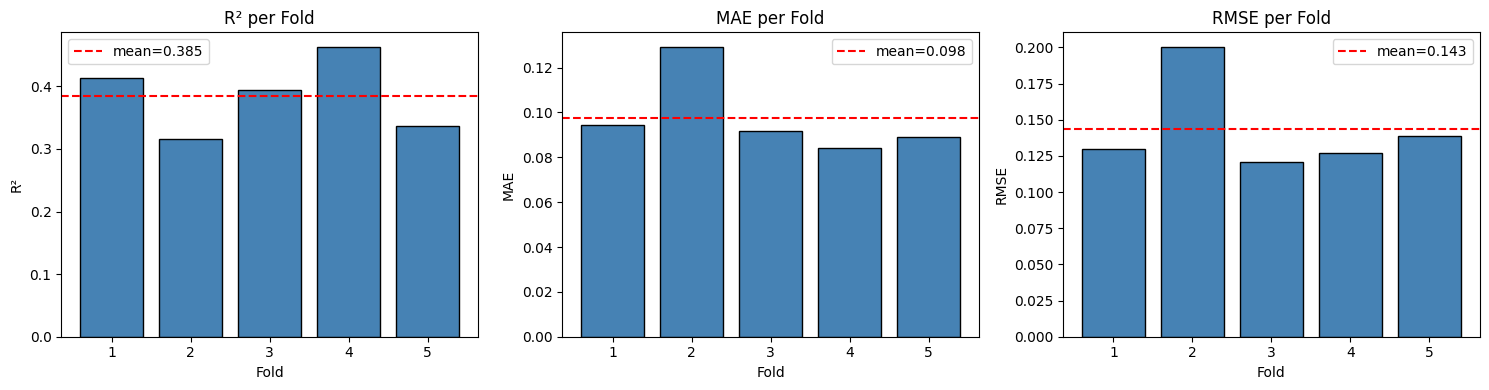


✅ Saved: /content/drive/MyDrive/ResumeProject/extra_analysis/cv_folds_ridge.png


In [5]:
# ========== CELL 5: HELD-OUT ANALYSIS (5-FOLD CV) ==========
from sklearn.model_selection import KFold

# Combine train + test for cross-validation (more robust)
all_data = pd.concat([train, test], ignore_index=True)
X_all = all_data['Combined'].values
y_all = all_data['Avg'].values

print("=" * 60)
print("📊 5-FOLD CROSS-VALIDATION — RIDGE")
print("=" * 60)
print(f"Total samples: {len(all_data)}\n")

# Pipeline: TF-IDF + Ridge
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=2000, ngram_range=(1,1),
                              min_df=2, max_df=0.90,
                              stop_words='english', sublinear_tf=True)),
    ('ridge', Ridge(alpha=1.0, random_state=42))
])

# 5-fold CV — multiple metrics
kf = KFold(n_splits=5, shuffle=True, random_state=42)

r2_scores = []
mae_scores = []
rmse_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_all), 1):
    X_tr, X_val = X_all[train_idx], X_all[val_idx]
    y_tr, y_val = y_all[train_idx], y_all[val_idx]

    pipeline.fit(X_tr, y_tr)
    pred = np.clip(pipeline.predict(X_val), 0, 1)

    r2 = r2_score(y_val, pred)
    mae = mean_absolute_error(y_val, pred)
    rmse = np.sqrt(mean_squared_error(y_val, pred))

    r2_scores.append(r2); mae_scores.append(mae); rmse_scores.append(rmse)
    print(f"   Fold {fold}: R²={r2:.4f} | MAE={mae:.4f} | RMSE={rmse:.4f}")

print(f"\n📊 Average across 5 folds:")
print(f"   R²:   {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}")
print(f"   MAE:  {np.mean(mae_scores):.4f} ± {np.std(mae_scores):.4f}")
print(f"   RMSE: {np.mean(rmse_scores):.4f} ± {np.std(rmse_scores):.4f}")

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, (name, scores) in enumerate([('R²', r2_scores), ('MAE', mae_scores), ('RMSE', rmse_scores)]):
    axes[i].bar(range(1, 6), scores, color='steelblue', edgecolor='black')
    axes[i].axhline(np.mean(scores), color='red', linestyle='--', label=f'mean={np.mean(scores):.3f}')
    axes[i].set_xlabel('Fold'); axes[i].set_ylabel(name); axes[i].set_title(f'{name} per Fold')
    axes[i].set_xticks(range(1, 6))
    axes[i].legend()
plt.tight_layout()
plt.savefig(f'{EXTRA_DIR}/cv_folds_ridge.png', dpi=150, bbox_inches='tight')
plt.show()

# Save
with open(f'{EXTRA_DIR}/cv_results.txt', 'w') as f:
    f.write(f"5-fold CV R²: {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}\n")
    f.write(f"5-fold CV MAE: {np.mean(mae_scores):.4f} ± {np.std(mae_scores):.4f}\n")
    f.write(f"5-fold CV RMSE: {np.mean(rmse_scores):.4f} ± {np.std(rmse_scores):.4f}\n")
    for i, (r2, mae, rmse) in enumerate(zip(r2_scores, mae_scores, rmse_scores), 1):
        f.write(f"Fold {i}: R²={r2:.4f}, MAE={mae:.4f}, RMSE={rmse:.4f}\n")

print(f"\n✅ Saved: {EXTRA_DIR}/cv_folds_ridge.png")

📊 LABEL MUTATION ANALYSIS — RIDGE
  Mutation % |     Method |    Test R² |   Test MAE |  Test RMSE
----------------------------------------------------------------------
          0% |       none |     0.3798 |     0.0807 |     0.1251
         10% |       flip |     0.1214 |     0.1110 |     0.1489
         10% |      noise |     0.3863 |     0.0795 |     0.1244
         10% |     random |     0.3413 |     0.0861 |     0.1289
         20% |       flip |    -0.3065 |     0.1587 |     0.1815
         20% |      noise |     0.3494 |     0.0820 |     0.1281
         20% |     random |     0.2692 |     0.1013 |     0.1358
         30% |       flip |    -0.8774 |     0.1933 |     0.2176
         30% |      noise |     0.3461 |     0.0849 |     0.1284
         30% |     random |     0.1467 |     0.1212 |     0.1467
         50% |       flip |    -3.4118 |     0.3145 |     0.3336
         50% |      noise |     0.3329 |     0.0846 |     0.1297
         50% |     random |    -0.4600 |     0.164

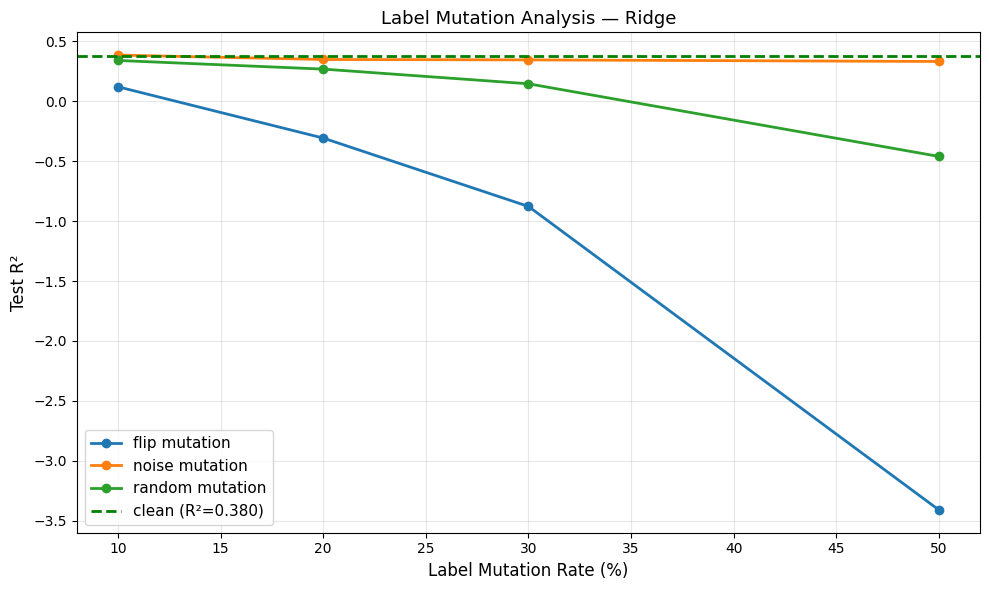


📊 Robustness Summary:
   flip: R² drop at 10% = +0.2584
   noise: R² drop at 10% = -0.0065
   random: R² drop at 10% = +0.0384

✅ Saved: /content/drive/MyDrive/ResumeProject/extra_analysis/label_mutation_ridge.png
✅ Saved: /content/drive/MyDrive/ResumeProject/extra_analysis/label_mutation_results.csv


In [6]:
# ========== CELL 6: LABEL MUTATION ANALYSIS ==========
import random
random.seed(42)
np.random.seed(42)

def mutate_labels(y, rate, method='flip'):
    """Mutate labels for robustness test."""
    y_mut = y.copy()
    n = len(y)
    n_mut = int(n * rate)
    idx = np.random.choice(n, n_mut, replace=False)

    if method == 'flip':
        y_mut[idx] = 1.0 - y_mut[idx]       # flip good↔bad
    elif method == 'noise':
        y_mut[idx] += np.random.normal(0, 0.2, n_mut)
        y_mut = np.clip(y_mut, 0, 1)
    elif method == 'random':
        y_mut[idx] = np.random.uniform(0, 1, n_mut)

    return y_mut

# Use training data (241 samples)
X_train_text = train['Combined'].values
y_train_orig = train['Avg'].values

# Vectorize once
vec_lm = TfidfVectorizer(max_features=2000, stop_words='english', sublinear_tf=True)
X_tr_vec = vec_lm.fit_transform(X_train_text)
X_te_vec = vec_lm.transform(test['Combined'].values)

print("=" * 80)
print("📊 LABEL MUTATION ANALYSIS — RIDGE")
print("=" * 80)
print(f"{'Mutation %':>12} | {'Method':>10} | {'Test R²':>10} | {'Test MAE':>10} | {'Test RMSE':>10}")
print("-" * 70)

results_lm = []

for rate in [0.0, 0.10, 0.20, 0.30, 0.50]:
    for method in (['none'] if rate == 0.0 else ['flip', 'noise', 'random']):
        y_mutated = y_train_orig.copy() if rate == 0.0 else mutate_labels(y_train_orig, rate, method)

        model = Ridge(alpha=1.0, random_state=42)
        model.fit(X_tr_vec, y_mutated)
        pred = np.clip(model.predict(X_te_vec), 0, 1)

        r2   = r2_score(y_test, pred)
        mae  = mean_absolute_error(y_test, pred)
        rmse = np.sqrt(mean_squared_error(y_test, pred))

        results_lm.append({'rate': rate, 'method': method, 'r2': r2, 'mae': mae, 'rmse': rmse})
        print(f"{rate*100:>11.0f}% | {method:>10} | {r2:>10.4f} | {mae:>10.4f} | {rmse:>10.4f}")

# Visualize
df_lm = pd.DataFrame(results_lm)
fig, ax = plt.subplots(figsize=(10, 6))
for method in ['flip', 'noise', 'random']:
    subset = df_lm[df_lm['method'] == method]
    ax.plot(subset['rate'] * 100, subset['r2'], marker='o', linewidth=2, label=f'{method} mutation')

# Add clean baseline
clean_r2 = df_lm[df_lm['method'] == 'none']['r2'].values[0]
ax.axhline(clean_r2, color='green', linestyle='--', linewidth=2, label=f'clean (R²={clean_r2:.3f})')

ax.set_xlabel('Label Mutation Rate (%)', fontsize=12)
ax.set_ylabel('Test R²', fontsize=12)
ax.set_title('Label Mutation Analysis — Ridge', fontsize=13)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{EXTRA_DIR}/label_mutation_ridge.png', dpi=150, bbox_inches='tight')
plt.show()

# Robustness summary
print("\n📊 Robustness Summary:")
for method in ['flip', 'noise', 'random']:
    subset = df_lm[df_lm['method'] == method]
    drop_10 = clean_r2 - subset[subset['rate'] == 0.10]['r2'].values[0]
    print(f"   {method}: R² drop at 10% = {drop_10:+.4f}")

# Save
df_lm.to_csv(f'{EXTRA_DIR}/label_mutation_results.csv', index=False)
with open(f'{EXTRA_DIR}/label_mutation_summary.txt', 'w') as f:
    f.write(f"Clean R²: {clean_r2:.4f}\n\n")
    for _, row in df_lm.iterrows():
        f.write(f"rate={row['rate']:.2f}, method={row['method']}, R²={row['r2']:.4f}\n")

print(f"\n✅ Saved: {EXTRA_DIR}/label_mutation_ridge.png")
print(f"✅ Saved: {EXTRA_DIR}/label_mutation_results.csv")

In [7]:
# ========== CELL 7: FINAL SUMMARY ==========
import os

print("=" * 70)
print("📊 GUIDE'S 4 REQUESTS — SUMMARY")
print("=" * 70)

print(f"\n1️⃣  AUC-ROC:")
print(f"   → AUC score = {auc:.4f}")
print(f"   → Chart: auc_roc_ridge.png")

print(f"\n2️⃣  Confusion Matrix:")
print(f"   → TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"   → Accuracy={accuracy:.4f}, Precision={precision:.4f}, Recall={recall:.4f}, F1={f1:.4f}")
print(f"   → Chart: confusion_matrix_ridge.png")

print(f"\n3️⃣  Held-Out (5-Fold CV):")
print(f"   → R² = {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}")
print(f"   → MAE = {np.mean(mae_scores):.4f}")
print(f"   → Chart: cv_folds_ridge.png")

print(f"\n4️⃣  Label Mutation:")
print(f"   → Clean R²: {clean_r2:.4f}")
print(f"   → Robustness: see label_mutation_ridge.png")
print(f"   → CSV: label_mutation_results.csv")

print(f"\n📁 All files in: {EXTRA_DIR}/")
for f in sorted(os.listdir(EXTRA_DIR)):
    p = f'{EXTRA_DIR}/{f}'
    if os.path.isfile(p):
        print(f"   - {f}  ({os.path.getsize(p)/1024:.1f} KB)")

📊 GUIDE'S 4 REQUESTS — SUMMARY

1️⃣  AUC-ROC:
   → AUC score = 0.8991
   → Chart: auc_roc_ridge.png

2️⃣  Confusion Matrix:
   → TN=0, FP=4, FN=0, TP=57
   → Accuracy=0.9344, Precision=0.9344, Recall=1.0000, F1=0.9661
   → Chart: confusion_matrix_ridge.png

3️⃣  Held-Out (5-Fold CV):
   → R² = 0.3848 ± 0.0530
   → MAE = 0.0977
   → Chart: cv_folds_ridge.png

4️⃣  Label Mutation:
   → Clean R²: 0.3798
   → Robustness: see label_mutation_ridge.png
   → CSV: label_mutation_results.csv

📁 All files in: /content/drive/MyDrive/ResumeProject/extra_analysis/
   - auc_results.txt  (0.1 KB)
   - auc_roc_ridge.png  (55.2 KB)
   - confusion_matrix_results.txt  (0.1 KB)
   - confusion_matrix_ridge.png  (31.7 KB)
   - cv_folds_ridge.png  (56.4 KB)
   - cv_results.txt  (0.3 KB)
   - label_mutation_results.csv  (0.9 KB)
   - label_mutation_ridge.png  (81.3 KB)
   - label_mutation_summary.txt  (0.5 KB)
